# Checkpoint 2: Same County, Different Weather? Comparing Four Prince George's County Weather Stations
Group Members & Contributions: 

Aashreya: Data Pre-Processing

Dia: Summary Statistics

Natalie, Jenny, Andrew: Paired t-test, correlation test

Luna: t-test, Correlation, and Overlapping Graphs

## Part 1: Data Pre-processing

### Importing:

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats 
import numpy as np
import matplotlib.dates as mdates

df = pd.read_csv("dailyweatherdata.csv")
df.head()

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,PRCP,SNOW,SNWD,TMAX,TMIN
0,USC00189070,"UPPER MARLBORO 3 NNW, MD US",38.8519,-76.7683,39.6,2000-01-01,0.0,0.0,0.0,57.0,26.0
1,USC00189070,"UPPER MARLBORO 3 NNW, MD US",38.8519,-76.7683,39.6,2000-01-02,0.0,0.0,0.0,59.0,26.0
2,USC00189070,"UPPER MARLBORO 3 NNW, MD US",38.8519,-76.7683,39.6,2000-01-03,0.0,0.0,0.0,68.0,49.0
3,USC00189070,"UPPER MARLBORO 3 NNW, MD US",38.8519,-76.7683,39.6,2000-01-04,0.0,0.0,0.0,70.0,57.0
4,USC00189070,"UPPER MARLBORO 3 NNW, MD US",38.8519,-76.7683,39.6,2000-01-05,1.1,0.0,0.0,72.0,38.0


In [36]:
df.dtypes

STATION          str
NAME             str
LATITUDE     float64
LONGITUDE    float64
ELEVATION    float64
DATE             str
PRCP         float64
SNOW         float64
SNWD         float64
TMAX         float64
TMIN         float64
dtype: object

### Parse:

In [37]:
# string to date, then pulling out year and month as ints
df["DATE"] = pd.to_datetime(df["DATE"])
df["YEAR"] = df["DATE"].dt.year
df["MONTH"] = df["DATE"].dt.month

#find any impossible rows (ex: low temp higher than the high temp)
bad = df[df["TMIN"] > df["TMAX"]]
print("Rows where TMIN > TMAX:", len(bad))
bad[["NAME", "DATE", "TMAX", "TMIN"]]

Rows where TMIN > TMAX: 5


,NAME,DATE,TMAX,TMIN
6986,"BELTSVILLE, MD US",2002-07-22,22.0,69.0
8386,"BELTSVILLE, MD US",2006-05-22,73.0,74.0
8717,"BELTSVILLE, MD US",2007-04-18,35.0,42.0
9531,"BELTSVILLE, MD US",2009-07-10,10.0,59.0
22679,"LAUREL 3 W, MD US",2000-06-11,71.0,96.0


In [38]:
# Set temperatures to NaN on the days that are impossible
df.loc[df["TMIN"] > df["TMAX"], ["TMAX", "TMIN"]] = float("nan")

#check for duplicate rows (same station on the same day)
print("Duplicate station days:", df.duplicated(["STATION", "DATE"]).sum())

Duplicate station days: 0


### Organize

In [39]:
#simpler column names
df = df.rename(columns={"STATION": "station_id", "NAME": "station", "DATE": "date", "YEAR": "year", 
"MONTH": "month", "TMAX":"tmax", "TMIN":"tmin", "PRCP":"prcp", "SNOW": "snow",
"SNWD": "snow_depth", "LATITUDE": "lat", "LONGITUDE": "lon", "ELEVATION": "elevation"})


#shorter station names
df["station"] = df["station"].replace({"BELTSVILLE, MD US": "Beltsville", "LAUREL 3 W, MD US": "Laurel",
"OXON HILL, MD US": "Oxon Hill", "UPPER MARLBORO 3 NNW, MD US": "Upper Marlboro"})

#sort so each station's days are in order 
df = df.sort_values(["station","date"]).reset_index(drop=True)

# Mark each day as rainy (1) or dry (0) so we can try to predict if it'll rain
df["rain_day"] = (df["prcp"] > 0).astype(int)

# If rain wasn't recorded, we don't know, so leave it blank instead of calling it dry
df.loc[df["prcp"].isna(), "rain_day"] = float("nan")

# Add yesterday's low, since it's a good clue for predicting today's low
df["tmin_yesterday"] = df.groupby("station")["tmin"].shift(1)

df.head()

,station_id,station,lat,lon,elevation,date,prcp,snow,snow_depth,tmax,tmin,year,month,rain_day,tmin_yesterday
0,USC00180700,Beltsville,39.0302,-76.9315,44.2,2000-01-01,0.00,0.0,0.0,55.0,27.0,2000,1,0.0,NaN
1,USC00180700,Beltsville,39.0302,-76.9315,44.2,2000-01-02,0.00,0.0,0.0,52.0,27.0,2000,1,0.0,27.0
2,USC00180700,Beltsville,39.0302,-76.9315,44.2,2000-01-03,0.00,0.0,0.0,67.0,48.0,2000,1,0.0,27.0
3,USC00180700,Beltsville,39.0302,-76.9315,44.2,2000-01-04,0.00,0.0,0.0,67.0,57.0,2000,1,0.0,48.0
4,USC00180700,Beltsville,39.0302,-76.9315,44.2,2000-01-05,1.22,0.0,0.0,69.0,36.0,2000,1,1.0,57.0


### Exploratory Data Analysis

In [40]:
print("Number of entries:", df.shape[0])
print("Number of features:", df.shape[1])
print(df["station"].value_counts())

Number of entries: 28270
Number of features: 15
station
Beltsville        9482
Oxon Hill         6982
Upper Marlboro    6053
Laurel            5753
Name: count, dtype: int64


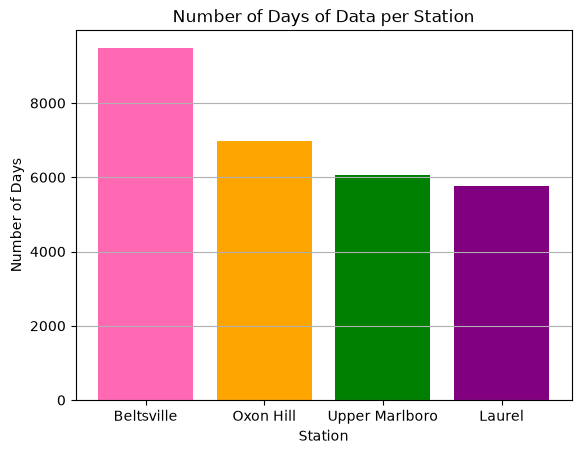

In [41]:
counts = df["station"].value_counts()
plt.figure
plt.bar(counts.index, counts.values, color=['hotpink', 'orange', 'green','purple'])
plt.title("Number of Days of Data per Station")
plt.xlabel("Station")
plt.ylabel("Number of Days")
plt.grid(axis="y")
plt.show()

This bar graph shows that our data set has data for the most number of days for the Beltsville Station with over 8000 days and that the area with the least number of days recorded is Laurel (having just under 6000). However, despite some of the differences in the amounts of data for each of the regions, it shows that there is enough data from each of the regions to be able to perform statistical analyses for each area.

In [42]:
# checking which years does each station has data for
pd.crosstab(df["year"], df["station"])

station,Beltsville,Laurel,Oxon Hill,Upper Marlboro
year,,,,
2000,366,366,0,366
2001,365,365,0,365
2002,365,365,213,365
2003,365,365,360,365
2004,366,366,362,366
2005,365,365,363,365
2006,365,335,365,335
2007,365,365,365,365
2008,366,366,366,366


In [43]:
# Fraction of missing values for each station
df.groupby("station")[["tmax", "tmin", "prcp", "snow", "snow_depth"]].apply(lambda g: g.isna().mean()).round(3)

,tmax,tmin,prcp,snow,snow_depth
station,,,,,
Beltsville,0.000,0.001,0.000,0.000,0.000
Laurel,0.242,0.243,0.066,0.257,0.303
Oxon Hill,0.012,0.011,0.004,0.008,0.019
Upper Marlboro,0.020,0.020,0.021,0.250,0.255


This dataset has 28,270 entries. Beltsville is overrepresented in the sample since it's the only station with data for all of the years. The other stations stopped reporting halfway through. Laurel is also missing about 24% of it's temperatures and Laurel and Upper Marlboro are missing about a quarter of their snow-depth values. Due to the stations not all having all of the years when we compare two stations we need to only sue dates both of them have. 

## Part 2: Summary Statistics

To break down our dataset's main attributes, the data in this dataframe records climate data including rain, snow, general precipitation, and temperature throughout 2 decades at four different stations in Maryland (Beltsville, Oxon Hill, Upper Marlboro, Laurel). Rain, snow, and precipitation are measured in inches, and temperature is in Fahrenheit. Let's first take a general look at this dataset to see what we'll focus on doing some summary stats for, what data types we have, and how many unique entries there are.

In [44]:
#doing a brief preliminary pass
df.describe()

,lat,lon,elevation,date,prcp,snow,snow_depth,tmax,tmin,year,month,rain_day,tmin_yesterday
count,28270.000000,28270.000000,28270.000000,28270,27730.000000,25216.000000,24848.000000,26670.000000,26665.000000,28270.000000,28270.000000,27730.000000,26663.000000
mean,38.945149,-76.905823,62.410743,2010-09-25 14:33:07.067562,0.126494,0.046923,0.164078,66.445632,46.880818,2010.238168,6.477184,0.325424,46.880996
min,38.795500,-76.994810,39.600000,2000-01-01 00:00:00,0.000000,0.000000,0.000000,14.000000,-4.000000,2000.000000,1.000000,0.000000,-4.000000
25%,38.851900,-76.931500,44.200000,2005-06-13 00:00:00,0.000000,0.000000,0.000000,52.000000,32.000000,2005.000000,4.000000,0.000000,32.000000
50%,39.030200,-76.931500,44.200000,2010-04-30 00:00:00,0.000000,0.000000,0.000000,68.000000,47.000000,2010.000000,6.000000,0.000000,47.000000
75%,39.030200,-76.900200,57.900000,2015-03-22 00:00:00,0.050000,0.000000,0.000000,82.000000,62.000000,2015.000000,9.000000,1.000000,62.000000
max,39.084700,-76.768300,121.900000,2025-12-31 00:00:00,7.460000,24.000000,28.000000,105.000000,83.000000,2025.000000,12.000000,1.000000,83.000000
std,0.117399,0.078949,30.787792,NaN,0.359662,0.523295,1.210890,18.266841,17.146657,6.384453,3.434827,0.468541,17.146456


In [45]:
#a look at data types and not null entries
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 28270 entries, 0 to 28269
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   station_id      28270 non-null  str           
 1   station         28270 non-null  str           
 2   lat             28270 non-null  float64       
 3   lon             28270 non-null  float64       
 4   elevation       28270 non-null  float64       
 5   date            28270 non-null  datetime64[us]
 6   prcp            27730 non-null  float64       
 7   snow            25216 non-null  float64       
 8   snow_depth      24848 non-null  float64       
 9   tmax            26670 non-null  float64       
 10  tmin            26665 non-null  float64       
 11  year            28270 non-null  int32         
 12  month           28270 non-null  int32         
 13  rain_day        27730 non-null  float64       
 14  tmin_yesterday  26663 non-null  float64       
dtypes: datetime64

In [46]:
#looking at the number of unique entries per column
df.nunique()

station_id           4
station              4
lat                  4
lon                  4
elevation            4
date              9497
prcp               307
snow                71
snow_depth          28
tmax                92
tmin                86
year                26
month               12
rain_day             2
tmin_yesterday      86
dtype: int64

It seems like the main attributes to conduct analysis with in this dataset are temperature, precipitation, and snow (which covers both snow depth and snow fall, which is just listed as snow in the df), and are categorized by what station it was recorded at, so let's take a better look at that data with respect to each station. Elevation and location data relating to each of the four stations might be relevant at somepoint, but given that there's only 4 unique rows of data amongst those columns (since the stations don't move), it's not as pertinent as the actual climate data. The tmin_yesterday and rain columns we made will come in handy for the ML part of the tutorial for later, so let's just focus on the main 3 attributes I mentioned above. It's also worth nothing that Beltsville has so much more data than any of the other stations, but each station has several thousand records regardless, so that should be good for our purposes. This data overrepresentation with Beltsville is important to take into account when doing analysis over specific periods of time for which Beltsville has data but the other stations don't. We will be keeping in mind for what years each station has data for (which was already explored in the EDA Section above).

First, let's look into temperature data. We only have the maximum and minimum temperatures recorded per each day, so to get something useful we can look at the daily temperature ranges. 

In [47]:
df['temperature_range'] = df['tmax'] - df['tmin']

#Now that I have the last column I'll make for this section, I want to know how many not null entries there are for each station in each column so I can accurately make claims on the outlier ratios later on
df.groupby('station').count()

,station_id,lat,lon,elevation,date,prcp,snow,snow_depth,tmax,tmin,year,month,rain_day,tmin_yesterday,temperature_range
station,,,,,,,,,,,,,,,
Beltsville,9482,9482,9482,9482,9482,9478,9479,9479,9478,9475,9482,9482,9478,9474,9475
Laurel,5753,5753,5753,5753,5753,5373,4273,4011,4361,4357,5753,5753,5373,4357,4357
Oxon Hill,6982,6982,6982,6982,6982,6956,6923,6846,6900,6903,6982,6982,6956,6902,6886
Upper Marlboro,6053,6053,6053,6053,6053,5923,4541,4512,5931,5930,6053,6053,5923,5930,5930


No matter what, we have at lesat 4,000 records of data for each column at each station. 

Note that all stations have different amounts of data, especially outside the years 2002-2016, so the boxplots below are just spotting for outliers in the overall data, and not for any direct comparisons between the stations themselves as that would be an unfair comparison. 

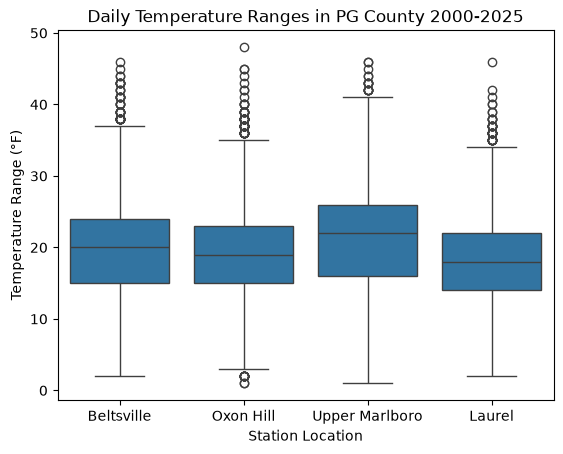

In [48]:
#making the boxplot for temperature range
plt.figure()
#keeping the order consistent with the number of days of data per station chart
ax = sns.boxplot(data = df, x = 'station', y = 'temperature_range', order = ['Beltsville', 'Oxon Hill', 'Upper Marlboro', 'Laurel'])
plt.title('Daily Temperature Ranges in PG County 2000-2025')
plt.xlabel('Station Location')
plt.ylabel('Temperature Range (°F)')
plt.show()

From the boxplot, it seems that most of the daily temperature ranges are around the 15-25 degrees Fahrenheit. Outliers for temperature range are typically around the 35-50 degrees Fahrenheit range. I'm interested to see these outliers and their dates, so I'll display some below, and how many there are:

In [49]:
#printing outliers
Q1 = df['temperature_range'].quantile(0.25)
Q3  = df['temperature_range'].quantile(0.75)
IQR = Q3-Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
outlierstemprange = df.loc[(df['temperature_range'] < lower) | (df['temperature_range'] > upper), ['station', 'temperature_range', 'date', 'year']]
#I want to know if all the stations have outliers:
outlierstemprange.groupby('station').head()

,station,temperature_range,date,year
13,Beltsville,39.0,2000-01-14,2000
16,Beltsville,43.0,2000-01-17,2000
97,Beltsville,40.0,2000-04-07,2000
99,Beltsville,44.0,2000-04-09,2000
302,Beltsville,38.0,2000-10-29,2000
9526,Laurel,38.0,2000-02-14,2000
9549,Laurel,39.0,2000-03-08,2000
9578,Laurel,38.0,2000-04-06,2000
10269,Laurel,40.0,2002-02-26,2002
10621,Laurel,42.0,2003-02-13,2003


In [50]:
#printing outlier sums
print("There are", outlierstemprange['temperature_range'].count(), "outliers for daily temperature range in this dataset across all stations from 2000-2025.")

There are 166 outliers for daily temperature range in this dataset across all stations from 2000-2025.


In [51]:
#displaying how many outliers there are by year and by station to get a better look at if there was any weird phenoma in a particular time range at a particular place. 
#This might be more helpful for further, future analysis.

pd.crosstab(outlierstemprange['station'], outlierstemprange['year'])

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
station,,,,,,,,,,,,,,,,,,,,,
Beltsville,5,1,3,1,0,1,5,2,2,1,...,4,2,1,0,0,1,2,1,4,3
Laurel,3,0,1,2,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Oxon Hill,0,0,0,3,0,2,2,4,1,0,...,2,1,3,2,1,2,0,0,0,0
Upper Marlboro,10,13,5,5,2,3,3,4,6,5,...,3,0,0,0,0,0,0,0,0,0


Not too many outliers it seems. Even for the station that only has around 4000 entries for temperature range (Laurel), if we assumed all the outliers belonged to that station (which we know is not true from the outlier dataframe printed above), 166 outliers would still be less than 5% of the data. There also doesn't seem to be a particular year with a lot of outliers, although Upper Marlboro in 2000 and 2001 did seem to have a bit more with 10 and 13. 

Now we'll look into individual temperature range distirbutions per station to get a better look at temperature data for each region, and also because not every station has data for the full 25 years. 

<Figure size 640x480 with 0 Axes>

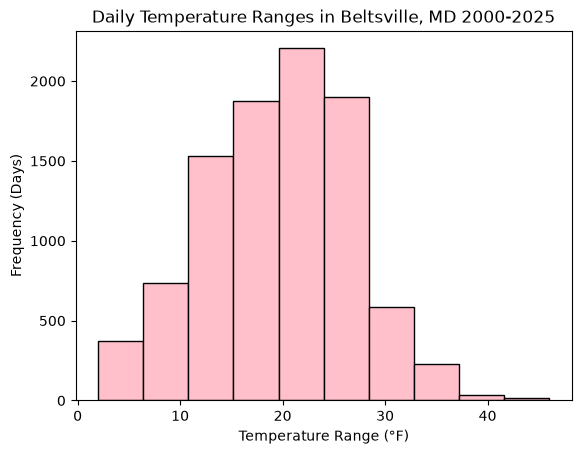

<Figure size 640x480 with 0 Axes>

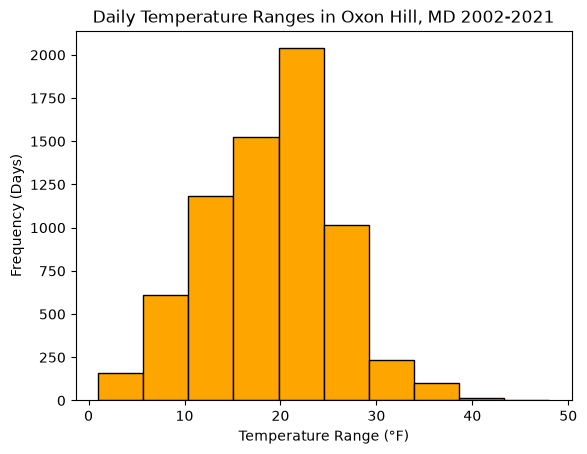

<Figure size 640x480 with 0 Axes>

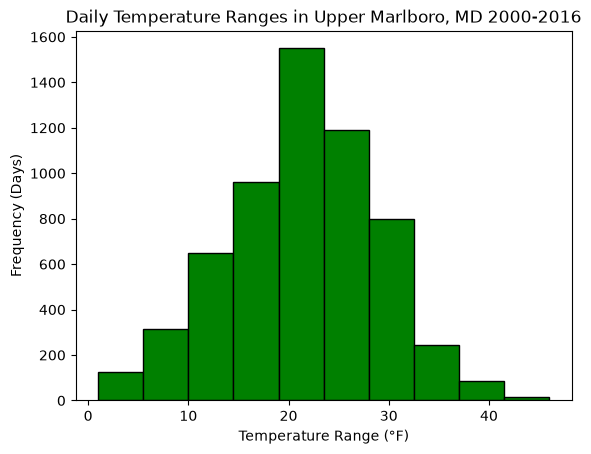

<Figure size 640x480 with 0 Axes>

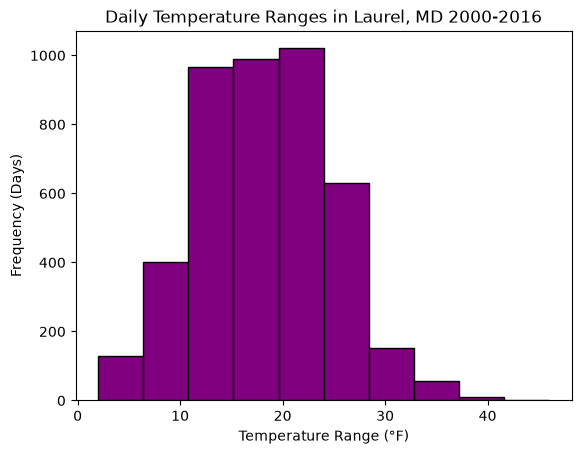

Text(0.5, 1.0, 'Daily Temperature Ranges, MD 2000-2016')

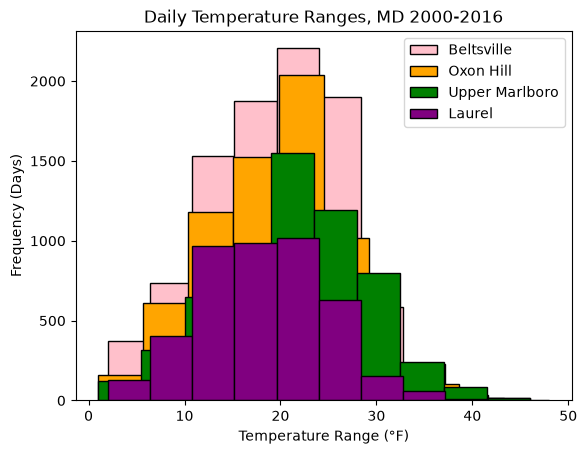

In [71]:
#individual histogram distributions of temperature ranges
stationstemprange = df.groupby('station')[['temperature_range']]

beltsvilletemprange = stationstemprange.get_group('Beltsville')
oxonhilltemprange = stationstemprange.get_group('Oxon Hill')
uppermarlborotemprange = stationstemprange.get_group('Upper Marlboro')
laureltemprange = stationstemprange.get_group('Laurel')

plt.figure()
beltsvilletemprange.hist(grid=False, edgecolor='black', color='pink')
plt.xlabel('Temperature Range (°F)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Temperature Ranges in Beltsville, MD 2000-2025')
plt.show()

plt.figure()
oxonhilltemprange.hist(grid=False, edgecolor='black', color='orange')
plt.xlabel('Temperature Range (°F)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Temperature Ranges in Oxon Hill, MD 2002-2021')
plt.show()

plt.figure()
uppermarlborotemprange.hist(grid=False, edgecolor='black', color='green')
plt.xlabel('Temperature Range (°F)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Temperature Ranges in Upper Marlboro, MD 2000-2016')
plt.show()

plt.figure()
laureltemprange.hist(grid=False, edgecolor='black', color='purple')
plt.xlabel('Temperature Range (°F)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Temperature Ranges in Laurel, MD 2000-2016')
plt.show()

fig, overlappingax = plt.subplots()
overlappingax.hist(beltsvilletemprange, edgecolor='black', color='pink', label='Beltsville')
overlappingax.hist(oxonhilltemprange, edgecolor='black', color='orange', label='Oxon Hill')
overlappingax.hist(uppermarlborotemprange, edgecolor='black', color='green', label='Upper Marlboro')
overlappingax.hist(laureltemprange, edgecolor='black', color='purple', label='Laurel')
overlappingax.legend()
plt.xlabel('Temperature Range (°F)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Temperature Ranges, MD 2000-2016')

The temperature distributions are pretty much all unimodal, and frequencies aside since they all have different records of data, they all generally have their highest bin around 20-25°F (that is, the histograms suggest that the daily temperature most frequently ranged between 20-25°F for all stations).

Now we'll look into precipitation data, and do similar analysis first with group boxplots and then individual histograms for each station. 

Again, it should be noted that these boxplots are showing data over all years even though not all stations have data for all years, as the purpose of this analysis is to look for outliers over the whole dataset, not to compare the stations to each other. 

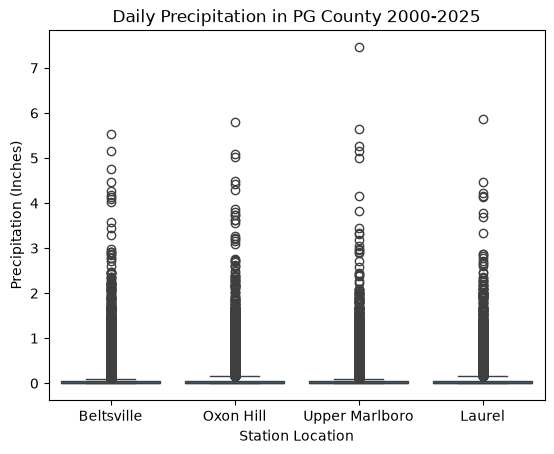

In [72]:
#making the boxplot
plt.figure()
ax = sns.boxplot(data = df, x = 'station', y = 'prcp', order = ['Beltsville', 'Oxon Hill', 'Upper Marlboro', 'Laurel'])
plt.title('Daily Precipitation in PG County 2000-2025')
plt.xlabel('Station Location')
plt.ylabel('Precipitation (Inches)')
plt.show()

In [73]:
#printing outliers
Q1 = df['prcp'].quantile(0.25)
Q3  = df['prcp'].quantile(0.75)
IQR = Q3-Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
outliersprcp = df.loc[(df['prcp'] < lower) | (df['prcp'] > upper), ['station', 'prcp', 'date', 'year']]
outliersprcp.groupby('station').head()

,station,prcp,date,year
4,Beltsville,1.22,2000-01-05,2000
10,Beltsville,0.75,2000-01-11,2000
19,Beltsville,0.18,2000-01-20,2000
23,Beltsville,0.30,2000-01-24,2000
24,Beltsville,0.53,2000-01-25,2000
9485,Laurel,1.12,2000-01-04,2000
9491,Laurel,0.78,2000-01-10,2000
9501,Laurel,0.41,2000-01-20,2000
9506,Laurel,0.71,2000-01-25,2000
9511,Laurel,0.27,2000-01-30,2000


In [74]:
#printing outlier sums
print("There are", outliersprcp['prcp'].count(), "many outliers for daily precipitation in this dataset across all stations from 2000-2025.")

There are 5335 many outliers for daily precipitation in this dataset across all stations from 2000-2025.


In [75]:
#displaying how many outliers there are by year and by station to get a better look at if there was any weird phenoma in a particular time range at a particular place. 
#This might be more helpful for further, future analysis, and also helps since not all stations hve data for all years. 

pd.crosstab(outliersprcp['station'], outliersprcp['year'])

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
station,,,,,,,,,,,,,,,,,,,,,
Beltsville,73,62,60,97,74,64,55,51,56,84,...,62,73,77,69,81,67,78,55,66,63
Laurel,75,63,57,92,79,59,46,55,64,89,...,0,0,0,0,0,0,0,0,0,0
Oxon Hill,0,0,39,97,73,62,63,58,67,92,...,69,62,86,79,91,43,0,0,0,0
Upper Marlboro,69,57,58,89,73,61,49,55,67,89,...,18,0,0,0,0,0,0,0,0,0


Okay, so there's quite a bit of outliers for precipitation, and all stations have outliers. However, this seems to be because there's just so much data for which daily precipitation is less than an inch/is 0 inches. The highest outlier recorded is about just 7 inches of precipitation daily, which doesn't seem like much, especially in rainy seasons. There are around 20% outliers over the whole dataset (from the count of this df we did earlier, 9,400+5,000+5,000+6,000 is around 27,400, a general estimate of how many not null values there are for precipitation data, and 5,335/27,400 is around 20%. This is very rough math, but the important thing is that 5,335 is a big amount of outliers regardless). However, the reason why these outliers are so weird is because they don't really seem significant. Getting more than 2 inches of precipitation doesn't register as super odd to me, although outliers don't necessrily always represent odd behavior, especially if just so much of the data is recorded as less since we're dealing with thousands of indices. 

If there's data for the station, there are outliers for that year in precipitation (because all of the zeroes are coming from the station not recording data, as Oxon Hill data ranges 2002-2021 and Laurel and Upper Marlboro 2000-2016), so there doesn't seem to be any one year responsible for this trend. 

Most of the precipitation records being 0 is kind of surprising to me, particularly because I feel like it's always raining around here. 

It is interesting that the IQR is so small, though, but it's probably because Maryland has been going through a drought for quite a long time. Perhaps this is something to look further into for our tutorial, especially looking into outliers by the seasons to see if there was actually rain in the expected rainy seasons! I do want to see, though, if any particular station is the reason for the lack of rain over the whole period of time, so let's make some histograms. 

<Figure size 640x480 with 0 Axes>

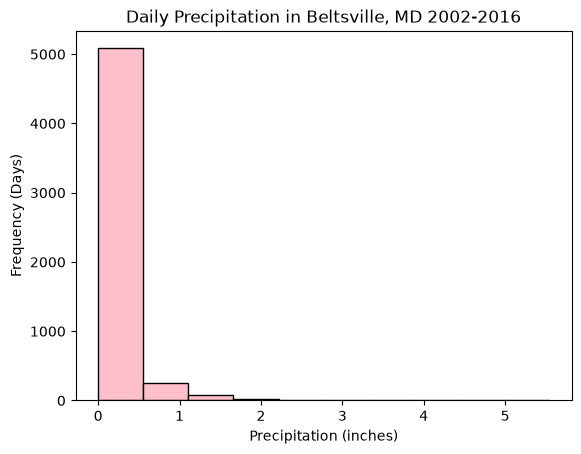

<Figure size 640x480 with 0 Axes>

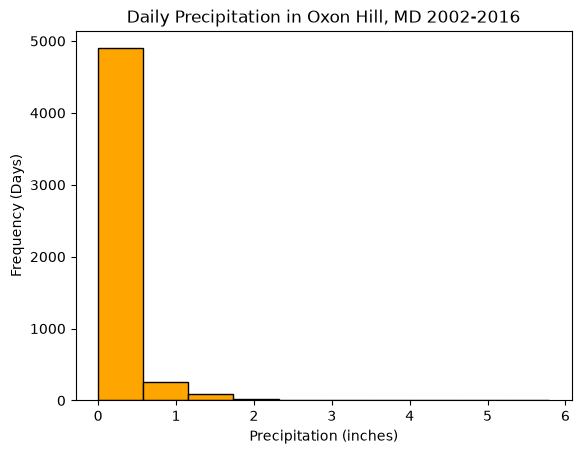

<Figure size 640x480 with 0 Axes>

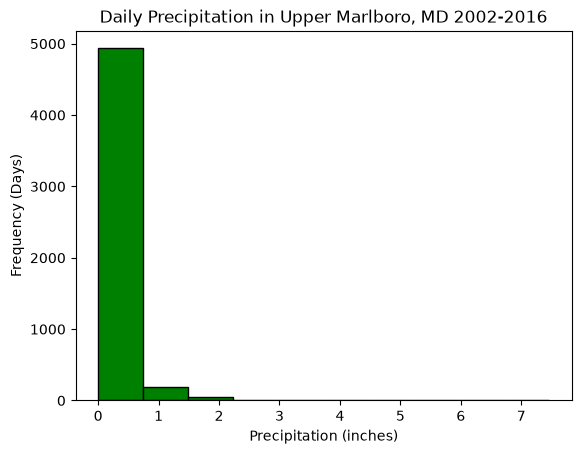

<Figure size 640x480 with 0 Axes>

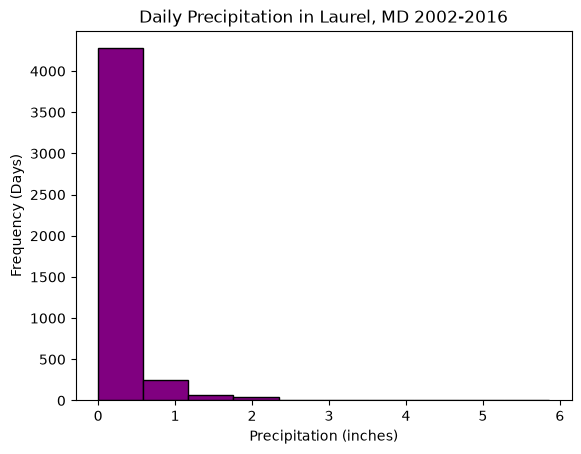

Text(0.5, 1.0, 'Daily Precipitation, MD 2002-2016')

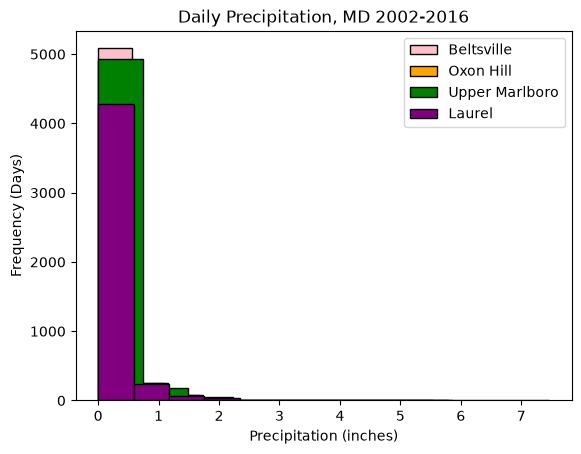

In [87]:
#Grouped histograms per station
#to get rid of the extra data Beltsville has and just generally make our comparison even, we'll just filter down to the range they all generally have data for, 
# which is 2002-2016, as we saw in the EDA section above

newdf = df[(df['year'] >= 2002) & (df['year'] <= 2016)]

stationsprcp = newdf.groupby('station')[['prcp']]

beltsvilleprcp = stationsprcp.get_group('Beltsville')
oxonhillprcp = stationsprcp.get_group('Oxon Hill')
uppermarlboroprcp = stationsprcp.get_group('Upper Marlboro')
laurelprcp = stationsprcp.get_group('Laurel')

plt.figure()
beltsvilleprcp.hist(grid=False, edgecolor='black', color='pink')
plt.xlabel('Precipitation (inches)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Precipitation in Beltsville, MD 2002-2016')
plt.show()

plt.figure()
oxonhillprcp.hist(grid=False, edgecolor='black', color='orange')
plt.xlabel('Precipitation (inches)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Precipitation in Oxon Hill, MD 2002-2016')
plt.show()

plt.figure()
uppermarlboroprcp.hist(grid=False, edgecolor='black', color='green')
plt.xlabel('Precipitation (inches)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Precipitation in Upper Marlboro, MD 2002-2016')
plt.show()

plt.figure()
laurelprcp.hist(grid=False, edgecolor='black', color='purple')
plt.xlabel('Precipitation (inches)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Precipitation in Laurel, MD 2002-2016')
plt.show()

fig, overlappingax = plt.subplots()
overlappingax.hist(beltsvilleprcp, edgecolor='black', color='pink', label='Beltsville')
overlappingax.hist(oxonhillprcp, edgecolor='black', color='orange', label='Oxon Hill')
overlappingax.hist(uppermarlboroprcp, edgecolor='black', color='green', label='Upper Marlboro')
overlappingax.hist(laurelprcp, edgecolor='black', color='purple', label='Laurel')
overlappingax.legend()
plt.xlabel('Precipitation (inches)')
plt.ylabel('Frequency (Days)')
plt.title('Daily Precipitation, MD 2002-2016')

Looking at these histograms, it doesn't seem like any one particular station is responsible for the significant records of 0 rain, especially given that theis is data over the same timeframe. When I looked at this data for each station's natural time frames, Beltsville had the most amount of days with 0 rain, but since that could be attributed to the fact that Beltsillve simply has the most data (in fact, thousands of records more than the other stations), I just got rid of those records and created a uniform time window to look at all 4 stations. It seems like, then, Maryland just does not get a lot of rain, or at least not around these stations/these stations don't record it. This'll be interesting to look into during the tutorial portion of this project. One direction we might take is looking specifically into time series to get time periods in which there is heavy precipitation, if there are any.

Looking into Snow Depth

These boxplots are showing data over all years even though not all stations have data for all years, as the purpose of this analysis is to look for outliers over the whole dataset, not to compare the stations to each other. 

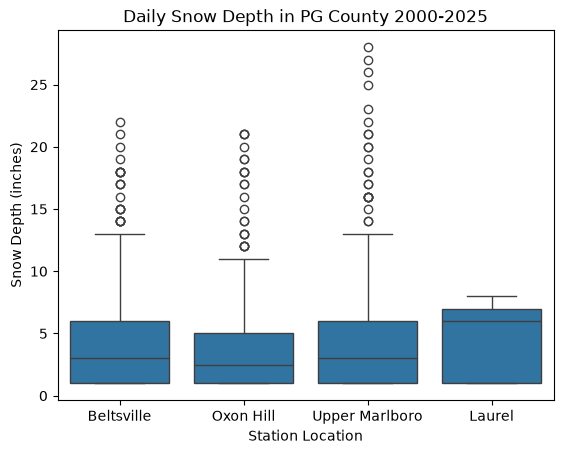

In [88]:
plt.figure()

#there's a lot of 0's in the snow depth, which we delete this time because they probably come from months when it doesn't usually snow, which isn't super helpful. 
#We want to know about snow data when we actually get snow since being in a snow "drought" is not consequential in the way an actual drought of precipitation/rain is.

helpful_snow_depth = df[df['snow_depth'] > 0].dropna(subset=['snow_depth'])
ax = sns.boxplot(data = helpful_snow_depth, x = 'station', y = 'snow_depth', order = ['Beltsville', 'Oxon Hill', 'Upper Marlboro', 'Laurel'])
plt.title('Daily Snow Depth in PG County 2000-2025')
plt.xlabel('Station Location')
plt.ylabel('Snow Depth (inches)')
plt.show()

Displaying outliers and how many there are:

In [89]:
Q1 = helpful_snow_depth['snow_depth'].quantile(0.25)
Q3  = helpful_snow_depth['snow_depth'].quantile(0.75)
IQR = Q3-Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
outlierssnowdepth = helpful_snow_depth.loc[(helpful_snow_depth['snow_depth'] < lower) | (helpful_snow_depth['snow_depth'] > upper), ['station', 'snow_depth', 'date', 'year']]
outlierssnowdepth.groupby('station').head()

,station,snow_depth,date,year
1143,Beltsville,18.0,2003-02-17,2003
1144,Beltsville,19.0,2003-02-18,2003
1145,Beltsville,17.0,2003-02-19,2003
1146,Beltsville,15.0,2003-02-20,2003
1147,Beltsville,15.0,2003-02-21,2003
15495,Oxon Hill,13.0,2003-02-17,2003
15496,Oxon Hill,13.0,2003-02-18,2003
15497,Oxon Hill,12.0,2003-02-19,2003
16575,Oxon Hill,13.0,2006-02-12,2006
17982,Oxon Hill,17.0,2009-12-20,2009


Laurel has no outliers for snow depth.

In [90]:
#printing outlier count
print("There are", outlierssnowdepth['snow_depth'].count(), "many outliers for snow depth in this dataset across all stations from 2000-2025.")

There are 79 many outliers for snow depth in this dataset across all stations from 2000-2025.


In [91]:
#displaying how many outliers there are by year and by station to get a better look at if there was any weird phenoma in a particular time range at a particular place. 
# This might be more helpful for further, future analysis.

pd.crosstab(outlierssnowdepth['station'], outlierssnowdepth['year'])

year,2000,2003,2006,2009,2010,2016
station,,,,,,
Beltsville,0,6,0,3,14,4
Oxon Hill,0,3,1,4,10,4
Upper Marlboro,3,5,0,2,16,4


For the amount of data we have for each station (thousands of records), there aren't many outliers (79 is less than 2% of all stations' data records since as we saw earlier, each station has at least 4,000 non-null entries for each of these climate attributes). That being said, the outliers we have seem significant. Oxon Hill, in particular, had almost 30 feet of snow on the ground at some point! This outlier probably shouldn't be removed in analysis, but kept with a special note (like this one). There seem to be the most outliers in 2010, so I guess there was probably a lot of snow then!

For analysis one direction we might take (just like with precipitation) is looking specifically into time series to get time periods in which there is heavy snowfall. We'd probably expect to get the winter months, but it'll make for a good exercise in a tutorial since we'll be looking at several months and several years in different locations, and there's many different ways to analyze such data. 

I made a histogram for each station for snow depth, but it didn't really add anything more than what the boxplot already showed us. Looking into each individual station distribution like that was most helpful for temperature ranges.

Now we move on to general snowfall data. 

These boxplots are showing data over all years even though not all stations have data for all years, as the purpose of this analysis is to look for outliers over the whole dataset, not to compare the stations to each other. 

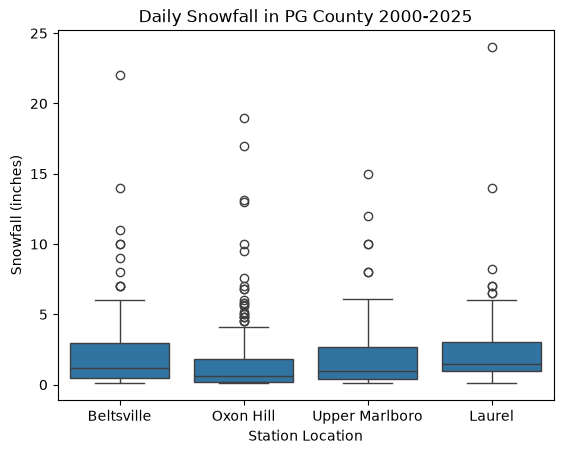

In [92]:
#boxplot
plt.figure()
#again, looking at snow data when it actually happens
helpful_snow = df[df['snow'] > 0].dropna(subset=['snow'])
ax = sns.boxplot(data = helpful_snow, x = 'station', y = 'snow', order = ['Beltsville', 'Oxon Hill', 'Upper Marlboro', 'Laurel'])
plt.title('Daily Snowfall in PG County 2000-2025')
plt.xlabel('Station Location')
plt.ylabel('Snowfall (inches)')
plt.show()

Displaying outliers and how many there are:

In [93]:
Q1 = helpful_snow['snow'].quantile(0.25)
Q3  = helpful_snow['snow'].quantile(0.75)
IQR = Q3-Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
outlierssnow = helpful_snow.loc[(helpful_snow['snow'] < lower) | (helpful_snow_depth['snow'] > upper), ['station', 'snow', 'date', 'year']]

outlierssnow.groupby('station').head()

,station,snow,date,year
24,Beltsville,6.0,2000-01-25,2000
1133,Beltsville,7.0,2003-02-07,2003
1142,Beltsville,7.0,2003-02-16,2003
1143,Beltsville,11.0,2003-02-17,2003
1486,Beltsville,6.0,2004-01-26,2004
10551,Laurel,6.0,2002-12-05,2002
15485,Oxon Hill,6.8,2003-02-07,2003
15494,Oxon Hill,6.0,2003-02-16,2003
15495,Oxon Hill,9.5,2003-02-17,2003
16225,Oxon Hill,5.7,2005-02-25,2005


In [94]:
#printing outlier count
print("There are", outlierssnow['snow'].count(), "outliers for snow depth in this dataset across all stations from 2000-2025.")

There are 46 outliers for snow depth in this dataset across all stations from 2000-2025.


In [95]:
#displaying how many outliers there are by year and by station to get a better look at if there was any weird phenoma in a particular time range at a particular place. 
#This might be more helpful for further, future analysis.

pd.crosstab(outlierssnow['station'], outlierssnow['year'])

year,2000,2002,2003,2004,2005,2006,2009,2010,2011,2014,2015,2016,2022
station,,,,,,,,,,,,,
Beltsville,1,0,3,1,0,1,3,3,0,2,1,2,1
Laurel,0,1,0,0,0,0,0,0,0,0,0,0,0
Oxon Hill,0,0,3,0,1,1,1,2,1,2,1,1,0
Upper Marlboro,1,0,3,0,0,0,3,3,0,2,0,2,0


It seems there's not too many outliers in the snowfall data, although Oxon Hill visibly has the most. 46 outliers over the whole data set is still not that many considering there's thousands of datapoints being recorded. Otherwise, the data seems to generally have a good range, especially given that, again, we're talking about thousands of rows of data for each region. Most snowfall seems to fall within the 0 to 5 inch range, particularly on the lower end of that range, which makes sense for Maryland. Interestingly enough, snowfall doesn't really relate to snow depth, and its general range is way smaller than snow depth, which one could argue might come from snow depth accumulating over multiple days of recorded snowfall. It'll be interesting to maybe look at time series between snow depth and snow fall and see if we can draw some evidence from that data. 

## Summary Stats Summary

Overall, this initial summary statistics analysis mainly looked into how many outliers each piece of climate data had, and how our continuous data was generally shaped. It seems the main attributes we'l be focusing on for general comparison and statistical analysis are precipitation, temperature, snow depth, and snow as they are continuous quantitative series with a lot of diverse, interesting information that'll be good for a tutorial. There are not many outliers for temperature range, and doing some kind of t-test for averages of temperature ranges might be interesting. There are many, many outliers in precipitation that will probably require further analysis and other techniques to understand what the best method of analysis for that data will be. There aren't many outliers for snow depth and snow fall, and looking into specific months when it snowed may be another good route for further analysis. To combine all the data, it may be interesting to look at temperature ranges correlating to if it snowed or not, and how snow depth correlates to snow fall, if at all. 


Something to be aware of is When comparing groups together in further analysis, we'll need to shave the data down to range from 2002-2016 since that is the range for which all 4 stations have data for at least some part of the year. 

## Part 3: Correlation

In [96]:
df.corr(numeric_only=True)

,lat,lon,elevation,prcp,snow,snow_depth,tmax,tmin,year,month,rain_day,tmin_yesterday,temperature_range,tmean
lat,1.000000,-0.003198,0.495827,-0.005171,-0.012951,-0.040745,-0.021833,0.001590,-0.016360,-0.005480,-0.014770,0.001674,-0.060776,-0.010559
lon,-0.003198,1.000000,-0.143024,-0.007181,0.010298,0.036088,-0.012549,-0.056384,-0.239783,-0.009124,-0.028470,-0.056362,0.106558,-0.034208
elevation,0.495827,-0.143024,1.000000,0.012552,-0.012702,-0.060173,-0.000099,0.042296,-0.186759,-0.010756,0.004086,0.042275,-0.104384,0.020792
prcp,-0.005171,-0.007181,0.012552,1.000000,0.121034,0.036167,0.018486,0.102445,-0.000182,0.025042,0.506377,0.102214,-0.203019,0.060402
snow,-0.012951,0.010298,-0.012702,0.121034,1.000000,0.503329,-0.168805,-0.139581,-0.003984,-0.085586,0.128944,-0.129683,-0.099061,-0.157738
snow_depth,-0.040745,0.036088,-0.060173,0.036167,0.503329,1.000000,-0.236667,-0.219190,-0.014336,-0.138917,0.038408,-0.217503,-0.079880,-0.232789
tmax,-0.021833,-0.012549,-0.000099,0.018486,-0.168805,-0.236667,1.000000,0.924192,0.009145,0.228838,-0.014502,0.882278,0.346494,0.982067
tmin,0.001590,-0.056384,0.042296,0.102445,-0.139581,-0.219190,0.924192,1.000000,0.020317,0.251359,0.104244,0.933083,-0.038043,0.979624
year,-0.016360,-0.239783,-0.186759,-0.000182,-0.003984,-0.014336,0.009145,0.020317,1.000000,-0.024035,0.021756,0.019944,-0.025861,0.014910
month,-0.005480,-0.009124,-0.010756,0.025042,-0.085586,-0.138917,0.228838,0.251359,-0.024035,1.000000,-0.034718,0.261015,-0.019037,0.244603


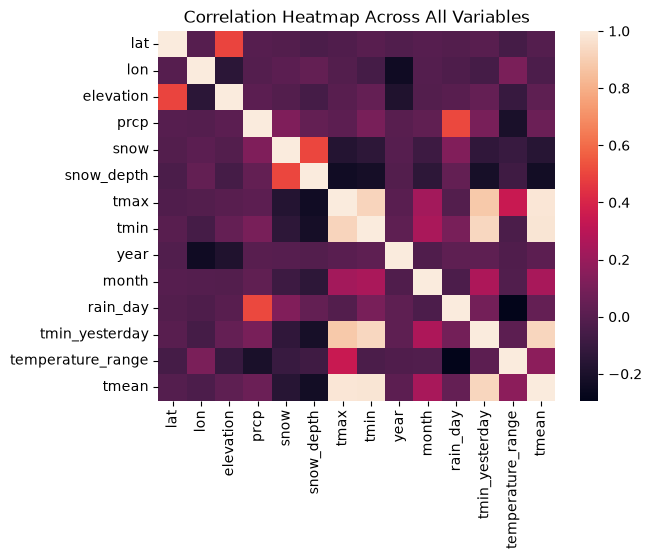

In [98]:
# heatmap for the correlation matrix

correlations = df.corr(numeric_only=True)
corrheatmap = sns.heatmap(correlations)
corrheatmap.set_title('Correlation Heatmap Across All Variables')
plt.show()

The Pearson correlation matrix shows several strong relationships between weather variables. The strongest positive correlations are between minimum temperature (tmin) and yesterday's minimum temperature (tmin_yesterday, r = 0.933), as well as maximum and minimum temperatures (r = 0.924). Snowfall and snow depth also have a moderate positive correlation (r = 0.503), while precipitation and rainy days are moderately correlated (r = 0.506). Temperature range has weak negative correlations with precipitation (r = -0.203) and rainy days (r = -0.294). Overall, temperature-related variables have the strongest correlations, while most geographical and temporal variables show relatively weak linear relationships with other features.

These correlations are shown on the heatmap with the strongest correlations showing up on the map as a lighter color and the weakest correlations showing up as a darker color. This heat map shows that each variable has a perfect correlation with itself as expected and depicted as the diagonal line of white squares. It also depicts the variables we identified as having the strongest correlations with a beige color and the variables we identified as having a moderate correlation with a red color. This helps to pick out which variables may have an stronger correlation quickly rather than individually looking at each number on the original correlation matrix.

## Part 4: Hypothesis Test

Hypothesis test: Is Beltsville warmer than Oxon Hill?

We use a paired t-test because both stations record temperature on the same days, so each shared date is one matched pair. We merge on date so only days both stations have are compared.

Null Hypothesis:The mean difference in daily temperature (Beltsville − Oxon Hill) is 0.

Alternative Hypothesis: The mean difference is not 0.

Significance level: α = 0.05

Note: We approximated the mean in daily temperature using (tmax + tmin)/2 not through specific "mean" data collected from the dataset. Since there was no specified variable for each of the days for the mean daily temperature in the dataset, this is the closest approximation that we can calculate for it. For all intents and purposes of this hypothesis test, this approximation should have minimal effect on the results of this test since the distributions for the ranges of the daily temperature of each station are all very similar. The ranges of the daily temperature for each station are centered around 20 degrees Fahrenheit (graphs shown in the Summary Statistics Section).

In [99]:
# daily mean temperature
df["tmean"] = (df["tmax"] + df["tmin"]) / 2

beltsville = df[df["station"] == "Beltsville"][["date", "tmean"]]
oxon = df[df["station"] == "Oxon Hill"][["date", "tmean"]]

# keep only dates both stations have + drop missing values
paired = beltsville.merge(oxon, on="date", suffixes=("_belts", "_oxon")).dropna()

print("Paired days:", len(paired))
print("Beltsville mean:", round(paired["tmean_belts"].mean(), 2))
print("Oxon Hill mean:", round(paired["tmean_oxon"].mean(), 2))

# paired t-test
t_stat, p_val = stats.ttest_rel(paired["tmean_belts"], paired["tmean_oxon"])
print("t =", round(t_stat, 3), " p =", p_val)

Paired days: 6867
Beltsville mean: 56.25
Oxon Hill mean: 57.66
t = -64.112  p = 0.0


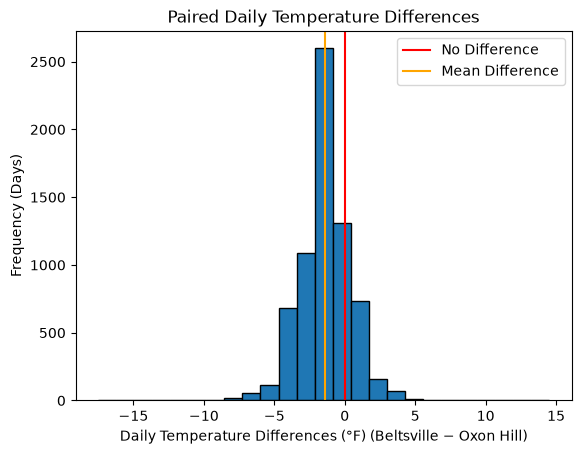

In [100]:
# histogram of the paired differences
diff = paired["tmean_belts"] - paired["tmean_oxon"]

plt.hist(diff, bins=25, edgecolor="black")
plt.axvline(0, color="red", label="No Difference")
plt.axvline(diff.mean(), color="orange", label="Mean Difference")
plt.xlabel("Daily Temperature Differences (°F) (Beltsville − Oxon Hill)")
plt.ylabel("Frequency (Days)")
plt.title("Paired Daily Temperature Differences")
plt.legend()
plt.show()

Result: We compared daily mean temperatures on 6,867 days that both stations had data. Beltsville averaged 56.25 °F and Oxon Hill averaged 57.66 °F, a difference of about 1.4 °F. The paired t-test gave t = -64.11 and p < 0.001.

Conclusion: Since p is less than 0.05, we reject the null hypothesis. There is strong evidence that Beltsville and Oxon Hill have different average daily temperatures, with Oxon Hill running about 1.4 °F warmer. One possible explanation is that Oxon Hill is more urban and closer to Washington, DC, but this test only shows that a difference exists, not why.

Caveat: Daily temperatures are correlated from one day to the next, so the effective sample size is smaller than 6,867 and the t-statistic is likely overstated. The difference is large enough relative to the day-to-day variation that the conclusion would almost certainly still hold.

The histogram of the paired daily temperature differences show where the distribution would be centered if there was no significant differences between the paired mean temperatures in Beltsville and Oxon Hill (the red line) and where the distribution is actually centered (the orange line). This histogram shows that the paired differences between these two locations are centered around -1.5 instead of 0. This shows that there is statistically significant (at alpha = 0.05) that Beltsville has slightly cooler mean temperatures than Oxon Hill.